# Pet Segmentation

Я выделяю питомца на фото. Обучение и проверка описаны ниже.

In [1]:
import csv
import hashlib
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageEnhance, ImageFilter
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet34_Weights, resnet34
from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny
from torchvision.models import ConvNeXt_Small_Weights, convnext_small
from torchvision.transforms import ColorJitter
from torchvision.models import ResNet50_Weights
from torchvision.models.segmentation import deeplabv3_resnet50

train = False
check_hold = False
predict = False
job = "res320"

data = Path("data")
runs = Path("runs")
common = dict(model="res34", size=320, batch=16, epochs=18, lr=3e-4,
              dice=0.5, edge=1.0, aug=True, keep=True, start=None)
jobs = {
    "base": dict(model="unet", size=256, epochs=30, lr=1e-4,
                 dice=0.0, aug=False, keep=False),
    "res320": {},
    "edge320": dict(edge=0.5),
    "big384": dict(model="big", size=384, batch=12, epochs=18, lr=4e-4, wide=True, small_bg=True, edge=0.65, soft=0.82),
    "convwide": dict(model="conv", size=384, batch=12, epochs=14, lr=2.5e-4, start="conv384", wide=True, edge=0.7),
    "lab384": dict(model="lab", size=384, batch=8, epochs=16, lr=4e-4, wide=True, small_bg=True, edge=0.7),
    "conv384": dict(model="conv", size=384, batch=12, epochs=14, lr=5e-4),
    "res448": dict(size=448, batch=8, epochs=8, lr=1e-4, start="res320"),
}
cfg = common | jobs[job]
workers = 0
seed = 42
device = torch.device("cuda" if train or check_hold or predict else "cpu")
if device.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("Для этого этапа нужна среда PyTorch с CUDA")
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(4)

if not (data / "split.json").is_file():
    raise FileNotFoundError("Сначала подготовь данные через data.py")
split_file = (data / "split.json").read_bytes()
split = json.loads(split_file)
split_id = hashlib.sha256(split_file).hexdigest()
audit = json.loads((data / "audit.json").read_text(encoding="utf-8"))
print(audit["sizes"], "пропущено:", len(audit["skipped"]))

{'train': 5863, 'val': 736, 'hold': 736, 'test': 349} пропущено: 14


## Данные

Маска хранит три значения: питомец, фон и край. В бинарной задаче питомец и край считаются одним классом. При изменении размера маски сохраняю исходные метки.

In [2]:
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
jitter = ColorJitter(0.18, 0.18, 0.15, 0.03)
wide_jitter = ColorJitter(0.35, 0.35, 0.3, 0.06)


def read_pic(path):
    with Image.open(path) as pic:
        return pic.convert("RGB")


def read_mask(name):
    with Image.open(data / "mask" / f"{name}.png") as pic:
        return Image.fromarray(np.array(pic, dtype=np.uint8))


def pair(name):
    return read_pic(data / "img" / f"{name}.jpg"), read_mask(name)


def scene(pic, mask, bg, bm, rng, solo, small_bg=True):
    core = np.array(mask)
    box = Image.fromarray(np.uint8((core == 1) | (core == 3))).getbbox()
    if box is None:
        return pic, mask
    pet, pm = pic.crop(box), mask.crop(box)
    if solo:
        bw, bh = bg.size
        divs = (3, 4, 6, 8) if small_bg else (3,)
        found = False
        for div in divs:
            w, h = max(1, bw // div), max(1, bh // div)
            for _ in range(16):
                x, y = rng.randint(0, bw - w), rng.randint(0, bh - h)
                area = (x, y, x + w, y + h)
                if bm.crop(area).getextrema() == (2, 2):
                    bg = bg.crop(area).resize((bw, bh), Image.Resampling.BILINEAR)
                    bm = Image.new("L", (bw, bh), 2)
                    found = True
                    break
            if found:
                break
    w, h = bg.size
    zoom = min(w / pet.width, h / pet.height) * rng.uniform(0.36, 0.86) ** 2
    size = (max(1, round(pet.width * zoom)), max(1, round(pet.height * zoom)))
    pet = pet.resize(size, Image.Resampling.BILINEAR)
    pm = pm.resize(size, Image.Resampling.NEAREST)
    code = np.array(pm)
    alpha = Image.fromarray(np.uint8(np.where(code == 1, 255, np.where(code == 3, 180, 0))))
    keep = Image.fromarray(np.uint8((code != 2) * 255))
    xy = (rng.randint(0, w - size[0]), rng.randint(0, h - size[1]))
    bg.paste(pet, xy, alpha)
    bm.paste(pm, xy, keep)
    return bg, bm


stress_ids = random.Random(85).sample(split["val"], 240)


def stress_pair(name):
    rng = random.Random(name + "_stress")
    pic, mask = pair(name)
    other = rng.choice(split["val"])
    bg, bm = pair(other)
    pic, mask = scene(pic, mask, bg, bm, rng, solo=True)
    pic = ImageEnhance.Contrast(pic).enhance(rng.uniform(0.65, 1.3))
    if rng.random() < 0.2:
        pic = pic.filter(ImageFilter.GaussianBlur(rng.uniform(0.4, 1.3)))
    return pic, mask


def pack(pic, mask, cfg, aug=False):
    size = cfg["size"]
    w, h = pic.size
    if aug:
        if random.random() < 0.5:
            pic = pic.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        if random.random() < 0.5:
            angle = random.uniform(-12, 12)
            pic = pic.rotate(angle, Image.Resampling.BILINEAR, fillcolor=(124, 116, 104))
            mask = mask.rotate(angle, Image.Resampling.NEAREST, fillcolor=0)
        if cfg.get("wide"):
            pic = wide_jitter(pic)
            if random.random() < 0.12:
                pic = pic.filter(ImageFilter.GaussianBlur(random.uniform(0.4, 1.4)))
            if random.random() < 0.08:
                pic = pic.convert("L").convert("RGB")
        else:
            pic = jitter(pic)

    if cfg["keep"]:
        scale = size / max(w, h)
        if aug:
            scale *= random.uniform(0.86, 1.0)
        w = max(1, round(w * scale))
        h = max(1, round(h * scale))
    else:
        w, h = size, size

    if aug:
        left = random.randint(0, size - w)
        top = random.randint(0, size - h)
    else:
        left = (size - w) // 2
        top = (size - h) // 2
    pic_box = Image.new("RGB", (size, size), (124, 116, 104))
    pic_box.paste(pic.resize((w, h), Image.Resampling.BILINEAR), (left, top))
    mask_box = Image.new("L", (size, size))
    if mask is not None:
        mask_box.paste(mask.resize((w, h), Image.Resampling.NEAREST), (left, top))

    x = torch.from_numpy(np.array(pic_box)).permute(2, 0, 1).float() / 255
    if cfg["model"] != "unet":
        x = (x - mean) / std
    mask = torch.from_numpy(np.array(mask_box))
    return x, mask, torch.tensor([left, top, w, h])


class Pets(Dataset):
    def __init__(self, part, cfg):
        self.ids = stress_ids if part == "stress" else split[part]
        self.part = part
        self.cfg = cfg

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        name = str(self.ids[i])
        if self.part == "test":
            pic = read_pic(data / "test" / f"{name}.png")
            mask = None
        elif self.part == "stress":
            pic, mask = stress_pair(name)
        else:
            pic, mask = pair(name)
            if self.part == "train" and self.cfg.get("wide") and random.random() < 0.55:
                bg, bm = pair(random.choice(self.ids))
                pic, mask = scene(pic, mask, bg, bm, random, solo=random.random() < 0.75,
                                  small_bg=self.cfg.get("small_bg", False))
        size = torch.tensor([pic.height, pic.width])
        x, mask, box = pack(pic, mask, self.cfg, self.part == "train" and self.cfg["aug"])
        return x, mask, box, size, name


def loader(part, cfg):
    return DataLoader(
        Pets(part, cfg), batch_size=cfg["batch"], shuffle=part == "train",
        num_workers=workers, pin_memory=device.type == "cuda",
        persistent_workers=workers > 0,
    )

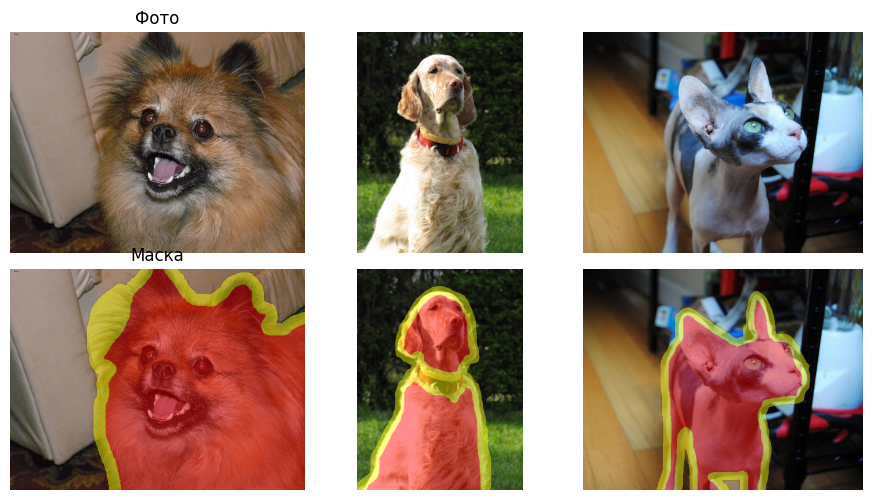

In [3]:
ids = random.Random(12).sample(split["train"], 3)
fig, axs = plt.subplots(2, len(ids), figsize=(9, 5))
for j, name in enumerate(ids):
    pic = read_pic(data / "img" / f"{name}.jpg")
    mask = np.array(read_mask(name))
    axs[0, j].imshow(pic)
    axs[1, j].imshow(pic)
    axs[1, j].imshow(np.ma.masked_where(mask == 2, mask), cmap="autumn", alpha=0.45)
    for ax in axs[:, j]:
        ax.axis("off")
axs[0, 0].set_title("Фото")
axs[1, 0].set_title("Маска")
plt.tight_layout()
plt.show()

## Модели

Сравнил U-Net с ResNet34 и ConvNeXt, а также DeepLabV3. Для энкодеров использовал стартовые веса ImageNet.

In [4]:
def conv(a, b):
    return nn.Sequential(
        nn.Conv2d(a, b, 3, padding=1, bias=False),
        nn.BatchNorm2d(b),
        nn.ReLU(inplace=True),
    )


def block(a, b):
    return nn.Sequential(conv(a, b), conv(b, b))


def resize(x, size):
    return F.interpolate(x, size=size, mode="bilinear", align_corners=False)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.down = nn.ModuleList(block(a, b) for a, b in zip([3, 32, 64, 128], [32, 64, 128, 256]))
        self.mid = block(256, 512)
        widths = [512, 256, 128, 64, 32]
        self.up = nn.ModuleList(nn.ConvTranspose2d(a, b, 2, stride=2) for a, b in zip(widths, widths[1:]))
        self.join = nn.ModuleList(block(a, b) for a, b in zip(widths, widths[1:]))
        self.head = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        skips = []
        for layer in self.down:
            x = layer(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.mid(x)
        for up, join, skip in zip(self.up, self.join, reversed(skips)):
            x = join(torch.cat([up(x), skip], dim=1))
        return self.head(x)[:, 0]


class ResUNet(nn.Module):
    def __init__(self, pretrained):
        super().__init__()
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        self.enc = resnet34(weights=weights)
        self.enc.fc = nn.Identity()
        self.join = nn.ModuleList([
            block(512 + 256, 160),
            block(160 + 128, 96),
            block(96 + 64, 64),
            block(64 + 64, 32),
        ])
        self.head = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        size = x.shape[-2:]
        a = self.enc.relu(self.enc.bn1(self.enc.conv1(x)))
        b = self.enc.layer1(self.enc.maxpool(a))
        c = self.enc.layer2(b)
        d = self.enc.layer3(c)
        x = self.enc.layer4(d)
        for layer, skip in zip(self.join, [d, c, b, a]):
            x = layer(torch.cat([resize(x, skip.shape[-2:]), skip], dim=1))
        return resize(self.head(x), size)[:, 0]


class ConvUNet(nn.Module):
    def __init__(self, pretrained, big=False):
        super().__init__()
        if big:
            weights = ConvNeXt_Small_Weights.DEFAULT if pretrained else None
            self.enc = convnext_small(weights=weights).features
        else:
            weights = ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
            self.enc = convnext_tiny(weights=weights).features
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.join = nn.ModuleList([
            block(768 + 384, 192),
            block(192 + 192, 128),
            block(128 + 96, 64),
            block(64 + 32, 32),
        ])
        self.head = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        size = x.shape[-2:]
        a = self.stem(x)
        b = self.enc[1](self.enc[0](x))
        c = self.enc[3](self.enc[2](b))
        d = self.enc[5](self.enc[4](c))
        x = self.enc[7](self.enc[6](d))
        for layer, skip in zip(self.join, [d, c, b, a]):
            x = layer(torch.cat([resize(x, skip.shape[-2:]), skip], dim=1))
        return resize(self.head(x), size)[:, 0]


class LabNet(nn.Module):
    def __init__(self, pretrained):
        super().__init__()
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = deeplabv3_resnet50(weights=None, weights_backbone=weights, num_classes=1)
        self.enc = model.backbone
        self.head = model.classifier

    def forward(self, x):
        p = self.head(self.enc(x)["out"])
        return resize(p, x.shape[-2:])[:, 0]


def make(cfg, pretrained=False):
    if cfg["model"] == "unet":
        return UNet()
    if cfg["model"] == "lab":
        return LabNet(pretrained)
    if cfg["model"] in ("conv", "big"):
        return ConvUNet(pretrained, cfg["model"] == "big")
    return ResUNet(pretrained)

## Ошибка и метрика

Для обучения пробую BCE вместе с Dice. На проверке считаю средний IoU по фото: пересечение масок делю на их объединение.

In [5]:
def target(mask):
    return (mask == 1) | (mask == 3)


def loss_fn(logit, mask, cfg):
    logit = logit.float()
    y = target(mask).float()
    if "soft" in cfg:
        y = torch.where(mask == 3, cfg["soft"], y)
    valid = mask != 0
    weight = valid.float() * torch.where(mask == 3, cfg["edge"], 1.0)
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (weight * bce).sum() / weight.sum().clamp_min(1)
    p = logit.sigmoid() * valid
    num = 2 * (p * y).sum(dim=(1, 2)) + 1
    den = p.sum(dim=(1, 2)) + y.sum(dim=(1, 2)) + 1
    dice = 1 - (num / den).mean()
    return (1 - cfg["dice"]) * bce + cfg["dice"] * dice


def iou(pred, true):
    union = np.count_nonzero(pred | true)
    if union == 0:
        return 1.0
    return np.count_nonzero(pred & true) / union


def restore(p, box, size):
    left, top, w, h = box.tolist()
    p = p[top:top+h, left:left+w]
    return resize(p[None, None], size.tolist())[0, 0].numpy()


@torch.inference_mode()
def probs(net, x, flip=False):
    with torch.autocast(x.device.type, dtype=torch.float16, enabled=x.is_cuda):
        p = net(x).float().sigmoid()
        if flip:
            q = net(x.flip(-1)).float().sigmoid().flip(-1)
            p = (p + q) / 2
    return p.cpu()


def score(net, dl, threshold=0.5, flip=False):
    net.eval()
    scores = []
    for x, _, boxes, sizes, names in dl:
        for p, box, size, name in zip(probs(net, x.to(device, non_blocking=True), flip), boxes, sizes, names):
            p = restore(p, box, size)
            y = target(np.array(read_mask(name)))
            scores.append(iou(p >= threshold, y))
    return float(np.mean(scores))

## Обучение

Сохраняю веса с лучшим IoU на валидации и пишу лог по эпохам. После обучения на той же части проверяю порог и отражение.

In [6]:
def save(pack, path):
    tmp = path.with_suffix(".tmp")
    torch.save(pack, tmp)
    tmp.replace(path)


def load(job):
    path = runs / job / "best.pt"
    pack = torch.load(path, map_location="cpu", weights_only=True)
    if pack["split"] != split_id:
        raise ValueError("Чекпоинт сделан с другим разбиением")
    net = make(pack["cfg"])
    net.load_state_dict(pack["weights"])
    return net.to(device).eval(), pack


def calibrate(net, dl):
    levels = [0.5, 0.45, 0.55, 0.4, 0.6, 0.35, 0.65]
    results = {(t, flip): [] for flip in (False, True) for t in levels}
    for x, _, boxes, sizes, names in dl:
        x = x.to(device, non_blocking=True)
        p = probs(net, x)
        q = probs(net, x.flip(-1)).flip(-1)
        both = (p + q) / 2
        for i, name in enumerate(names):
            y = target(np.array(read_mask(name)))
            for flip, batch in ((False, p), (True, both)):
                mask = restore(batch[i], boxes[i], sizes[i])
                for t in levels:
                    results[t, flip].append(iou(mask >= t, y))
    rows = [(t, flip, float(np.mean(values))) for (t, flip), values in results.items()]
    return rows


def fit(job, cfg):
    if device.type != "cuda":
        raise RuntimeError("Обучение запускаю только в среде с CUDA")
    folder = runs / job
    folder.mkdir(parents=True, exist_ok=False)
    train_dl = loader("train", cfg)
    val_dl = loader("val", cfg)
    if cfg["start"]:
        net, pack = load(cfg["start"])
        if pack["cfg"]["model"] != cfg["model"]:
            raise ValueError("Модели для дообучения отличаются")
    else:
        net = make(cfg, pretrained=True).to(device)

    if cfg["model"] == "unet":
        opt = torch.optim.Adam(net.parameters(), lr=cfg["lr"])
        sched = None
    else:
        opt = torch.optim.AdamW([
            {"params": net.enc.parameters(), "lr": cfg["lr"] / 5},
            {"params": [p for name, p in net.named_parameters() if not name.startswith("enc.")]},
        ], lr=cfg["lr"], weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, cfg["epochs"], eta_min=1e-6)

    scaler = torch.amp.GradScaler("cuda")
    best = -1
    with (folder / "log.csv").open("x", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "loss", "val_iou", "lr", "seconds"])
        for epoch in range(1, cfg["epochs"] + 1):
            start = time.perf_counter()
            net.train()
            total = 0.0
            count = 0
            for x, mask, _, _, _ in train_dl:
                x = x.to(device, non_blocking=True)
                mask = mask.to(device, non_blocking=True)
                opt.zero_grad(set_to_none=True)
                with torch.autocast("cuda", dtype=torch.float16):
                    logit = net(x)
                loss = loss_fn(logit, mask, cfg)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
                total += loss.detach().item() * len(x)
                count += len(x)
            val = score(net, val_dl)
            row = [epoch, total / count, val, opt.param_groups[-1]["lr"], time.perf_counter() - start]
            writer.writerow(row)
            f.flush()
            print(f"Эпоха {epoch}: loss {row[1]:.4f}, IoU {val:.4f}, {row[-1]:.0f} с", flush=True)
            if val > best:
                best = val
                pack = dict(weights=net.state_dict(), cfg=cfg, split=split_id,
                            epoch=epoch, val_iou=val, threshold=0.5, flip=False)
                save(pack, folder / "best.pt")
            if sched is not None:
                sched.step()

    net, pack = load(job)
    rows = calibrate(net, val_dl)
    with (folder / "cal.csv").open("x", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["threshold", "flip", "val_iou"])
        writer.writerows(rows)
    t, flip, val = max(rows, key=lambda row: row[-1])
    pack.update(threshold=t, flip=flip, val_iou=val)
    save(pack, folder / "best.pt")
    print(f"Лучший результат на val: {val:.4f}, порог {t}, отражение {flip}")

In [7]:
if train:
    fit(job, cfg)
else:
    print("Обучение выключено")

Обучение выключено


## Итоговая проверка

После выбора модели проверю её на отложенных фото Oxford. Для Kaggle восстановлю размер каждой маски и запишу её в RLE.

In [8]:
def rle_encode(mask):
    if mask.ndim != 2:
        raise ValueError("rle_encode expects a 2D mask")
    flat = np.ravel(mask.astype(np.uint8) > 0, order="F").astype(np.uint8)
    if np.sum(flat) == 0:
        return "EMPTY"
    flat = np.concatenate(([0], flat, [0]))
    changes = np.where(flat[1:] != flat[:-1])[0] + 1
    changes[1::2] -= changes[::2]
    return " ".join(map(str, changes.tolist()))


def submission(net, pack, dl, path):
    rows = []
    for x, _, boxes, sizes, names in dl:
        batch = probs(net, x.to(device, non_blocking=True), pack["flip"])
        for p, box, size, name in zip(batch, boxes, sizes, names):
            mask = restore(p, box, size) >= pack["threshold"]
            rows.append((int(name), rle_encode(mask)))
    if [name for name, _ in rows] != split["test"]:
        raise ValueError("ID в CSV не совпадают со списком Kaggle")
    with path.open("x", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["ImageID", "RLE"])
        writer.writerows(rows)
    print(f"Сохранено: {path}, строк: {len(rows)}")

In [9]:
if check_hold or predict:
    net, ckpt = load(job)
    if check_hold:
        val = score(net, loader("hold", ckpt["cfg"]), ckpt["threshold"], ckpt["flip"])
        print(f"IoU на отложенных фото: {val:.5f}")
        result = {"job": job, "epoch": ckpt["epoch"], "hold_iou": val}
        (runs / job / "hold.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    if predict:
        submission(net, ckpt, loader("test", ckpt["cfg"]), runs / job / "submission.csv")

## Проверка кода

Проверяю размеры тензоров, маски, IoU и RLE на CPU. Эта проверка не оценивает качество моделей.

In [10]:
test_cfg = cfg | {"size": 96}
x, mask, box, size, name = Pets("val", test_cfg)[0]
for model in ("unet", "res34", "conv", "lab", "big"):
    small = test_cfg | {"model": model}
    x, mask, box, size, name = Pets("val", small)[0]
    net = make(small).eval()
    with torch.inference_mode():
        logit = net(x[None])
    assert logit.shape == mask[None].shape
    assert torch.isfinite(loss_fn(logit, mask[None], small))
    assert restore(logit[0].sigmoid(), box, size).shape == tuple(size.tolist())

mask = np.array([[0, 1, 0], [1, 1, 0]], dtype=bool)
assert rle_encode(mask) == "2 3"
assert rle_encode(np.zeros((2, 3), dtype=bool)) == "EMPTY"
assert iou(mask, mask) == 1
assert iou(mask, ~mask) == 0
assert [str(i) for i in split["test"]] == [
    p.stem for p in sorted((data / "test").glob("*.png"), key=lambda p: int(p.stem))
]
print("Данные, выходы моделей, IoU и RLE проверены")

Данные, выходы моделей, IoU и RLE проверены


## Источники

[Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) · [U-Net](https://arxiv.org/abs/1505.04597) · [ResNet](https://arxiv.org/abs/1512.03385) · [Правила Kaggle](https://www.kaggle.com/competitions/cu-cv-pet-segmentation-challenge-2026/rules).

[ConvNeXt](https://arxiv.org/abs/2201.03545) · [Copy-Paste](https://arxiv.org/abs/2012.07177) · [DeepLabV3](https://arxiv.org/abs/1706.05587).

## Результаты

Я обучил модели используя Oxford-IIIT Pet. Исключил "Без питомца" 14 масок. Разделил фотографии на 3 части, а именно: train(5863), eval(736) и holdout(736). Для обучения поворачивал и отражал фото, а также менял его цвет.

Первая попытка дала 0,80519 на Kaggle, что для меня было маловато, я добавил перенос на другой фон и уменьшение питомца. На eval, а также на кадрах c мелкими питомцами, выбрал convwide+lab384+big384. Iou: **0.93558** на eval (последняя попытка), **0.91535** на мелких питомцах, **0.93853** на holdout.

На публичной части kaggle получил **0.82659** — **7 баллов** по правилам соревнования.

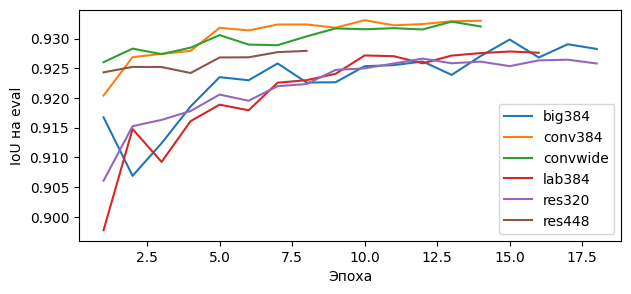

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
for path in sorted(runs.glob("*/log.csv")):
    with path.open(encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    ax.plot([int(row["epoch"]) for row in rows],
            [float(row["val_iou"]) for row in rows], label=path.parent.name)
ax.set(xlabel="Эпоха", ylabel="IoU на eval")
ax.legend()
plt.show()

In [12]:
export = False
if export:
    from mix import final

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True
    final(globals(), "test", "reproduced.csv")